# RQ1: Psychosocial factors across TBe/PBu groups

**Aim:** Describe which stressors, relationships, emotions, and responses appear in posts labeled **Neither**, **TBe only**, **PBu only**, or **Both**, and estimate their associations after accounting for other tags.

**Input:** `Easy version.xlsx`, worksheet `qwen3.5`. These Qwen 3.5 labels were already reviewed by your lab. The **MINDMINER Master Annotation Codebook v2.0** supplies the permitted tag names and meanings (31 active tags across four fields). We do not relabel posts.

**Only two RQ1 analyses:**

1. **Prevalence analysis:** Count the posts with each tag in each group and divide by the number of posts in that group. Show four publication-style purple heatmaps and a CSV table.
2. **Nominal (multinomial) logistic regression:** Model the four-category group outcome using the codebook tags and post length. Report adjusted relative risk ratios (RRRs), 95% confidence intervals, and FDR-adjusted p-values, with **Neither** as the reference.

**Not part of RQ1:** Standalone chi-square tests, Fisher pairwise tests, and association testing tables. These can be addressed in RQ4 instead.

**Interpretation limit:** Results show associations in annotated Reddit posts, not causal influences, diagnoses, or prevalence among people.


## 0. Setup and analysis decisions

Required Python packages: `pandas`, `numpy`, `statsmodels`, `scipy`, `matplotlib`, `openpyxl`, and `IPython`.

Your lab reviewed the annotations, so the main analysis includes posts even when the worksheet retains the historical `label_needs_review` flag. Change `EXCLUDE_REVIEW_FLAGGED` to `True` only to run an optional sensitivity check.

The codebook has 31 active tags. If a tag never occurs, such as `responses: other` in this workbook, it appears as **0%** in the prevalence output and cannot be estimated in regression. No positives are invented.

The workbook has an older evidence header (`evidence_relationships_unspecified`) for `relationships: other`; this requires manual verification of its meaning. The notebook does not automatically recode that tag.


In [ ]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from IPython.display import display
from scipy.stats import norm
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm

# -----------------------------------------------------------------------------
# USER SETTINGS
# -----------------------------------------------------------------------------
DATA_PATH = Path("Easy version.xlsx")
if not DATA_PATH.exists():
    DATA_PATH = Path("/mnt/data/Easy version.xlsx")  # Local execution fallback
SHEET_NAME = "qwen3.5"
OUTPUT_DIR = Path("RQ1_outputs_simplified")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EXCLUDE_REVIEW_FLAGGED = False  # Team says Qwen tags have been reviewed
MIN_REGRESSION_TAG_COUNT = 30   # Total positives required for regression
MIN_PER_GROUP = 5               # Positives and negatives in each group
FDR_ALPHA = 0.05

GROUP_ORDER = ["Neither", "TBe only", "PBu only", "Both"]
TAG_FIELDS = ["stressors", "relationships", "emotions", "responses"]

# All allowed tags in MINDMINER Master Annotation Codebook v2.0.
# Preserve exact field-specific distinctions, including separate 'other' tags.
CODEBOOK_TAGS = {
    "stressors": ["family conflict", "breakup or romance", "social isolation",
                  "financial", "study", "work", "health", "grief", "abuse", "other"],
    "relationships": ["partner", "family", "friend", "peer", "workplace",
                      "community", "other"],
    "emotions": ["loneliness", "guilt", "shame", "sadness", "anxiety",
                 "anger", "hopelessness", "other"],
    "responses": ["advice seeking", "emotional support seeking", "professional help",
                  "withdrawal", "positive coping", "other"],
}
assert sum(map(len, CODEBOOK_TAGS.values())) == 31

# Some source workbook evidence COLUMN HEADERS predate codebook v2.0.
# This maps where evidence is physically located. It does NOT equate
# 'unspecified' with the codebook meaning of relationship 'other'.
EVIDENCE_HEADER_ALIASES = {
    ("stressors", "other"): "evidence_stressors_",
    ("relationships", "other"): "evidence_relationships_unspecified",
    ("emotions", "other"): "evidence_emotions_",
}

def evidence_column(field, tag):
    return EVIDENCE_HEADER_ALIASES.get(
        (field, tag), f"evidence_{field}_{tag.replace(' ', '_')}"
    )

assert DATA_PATH.exists(), f"Input not found: {DATA_PATH.resolve()}"
print(f"Input workbook: {DATA_PATH.resolve()}")
print(f"Codebook: MINDMINER v2.0 | {sum(map(len, CODEBOOK_TAGS.values()))} active tags")
print(f"Worksheet: {SHEET_NAME} | Outputs: {OUTPUT_DIR.resolve()}")


Input workbook: /content/Easy version.xlsx
Codebook: MINDMINER v2.0 | 31 active tags
Worksheet: qwen3.5 | Outputs: /content/RQ1_outputs_simplified


## 1. Read the verified Qwen annotations, check labels, and define groups

- Use `belong` (TBe) and `burden` (PBu) to derive the four **mutually exclusive** groups.
- Read the evidence columns as well as tags so we can check codebook grounding.
- Drop rows with invalid original labels, missing post identifiers, or missing post text.
- Remove exact repeated posts using a case-insensitive whitespace-normalized text key.
- **Do not** infer TBe or PBu from the psychosocial tags.
- Rows with blank tag fields will be treated as having no positive named tag, **assuming the Qwen annotation is complete**. Empty fields do not count as a codebook tag.


In [ ]:
required_columns = ["post_id", "text_clean", "belong", "burden", *TAG_FIELDS]
optional_columns = ["split", "orig_row_id", "group", "label_needs_review",
                    "label_validation_issues"]

# Evidence columns are imported ONLY for quality checks, not model features.
needed = set(required_columns + optional_columns)
raw = pd.read_excel(
    DATA_PATH,
    sheet_name=SHEET_NAME,
    usecols=lambda name: name in needed or name.startswith("evidence_"),
    engine="openpyxl",
)
missing = sorted(set(required_columns) - set(raw.columns))
if missing:
    raise ValueError(f"Missing required source columns: {missing}")

initial_rows = len(raw)
df = raw.dropna(subset=["post_id"]).copy()
print(f"Rows read: {initial_rows:,} | rows with post ID: {len(df):,}")

for label in ["belong", "burden"]:
    df[label] = pd.to_numeric(df[label], errors="coerce")
invalid_label = ~df["belong"].isin([0, 1]) | ~df["burden"].isin([0, 1])
if invalid_label.any():
    print(f"Excluding {invalid_label.sum():,} rows with invalid original TBe/PBu labels")
    df = df.loc[~invalid_label].copy()

df = df.loc[
    df["text_clean"].notna() & df["text_clean"].astype(str).str.strip().ne("")
].copy()
df[["belong", "burden"]] = df[["belong", "burden"]].astype(int)

flag_col = "label_needs_review"
flagged = (pd.to_numeric(df[flag_col], errors="coerce").fillna(0).eq(1)
           if flag_col in df.columns else pd.Series(False, index=df.index))
print(f"Rows marked label_needs_review=1: {flagged.sum():,}")
if EXCLUDE_REVIEW_FLAGGED:
    df = df.loc[~flagged].copy()
    print("Sensitivity analysis: review-flagged rows excluded")
else:
    print("Primary analysis: review-flagged rows retained per team verification")

def normalize_for_dedup(value):
    return re.sub(r"\s+", " ", str(value)).strip().casefold()

df["_text_key"] = df["text_clean"].map(normalize_for_dedup)
duplicates = df.duplicated(subset=["_text_key"], keep="first")
print(f"Repeated texts removed: {duplicates.sum():,}")
df = df.loc[~duplicates].drop(columns=["_text_key"]).copy()

group_map = {(0, 0): "Neither", (1, 0): "TBe only",
             (0, 1): "PBu only", (1, 1): "Both"}
df["rq1_group"] = [group_map[(a, b)] for a, b in zip(df["belong"], df["burden"])]
df["rq1_group"] = pd.Categorical(df["rq1_group"], categories=GROUP_ORDER)

if "group" in df.columns:
    mismatch = df["group"].astype(str).str.strip().ne(df["rq1_group"].astype(str))
    if mismatch.any():
        print(f"Warning: {mismatch.sum():,} source group labels disagree with binary labels")

group_sizes = df["rq1_group"].value_counts().reindex(GROUP_ORDER, fill_value=0).astype(int)
if (group_sizes == 0).any():
    raise ValueError("At least one TBe/PBu group has no posts")

print(f"\nUnique posts analyzed: {len(df):,}")
display(group_sizes.rename("post_count").to_frame())


Rows read: 3,522 | rows with post ID: 3,522
Rows marked label_needs_review=1: 508
Primary analysis: review-flagged rows retained per team verification
Repeated texts removed: 3

Unique posts analyzed: 3,519


,post_count
rq1_group,
Neither,1122
TBe only,1251
PBu only,472
Both,674


## 2. Parse tags using codebook v2.0 as the **only** allowed vocabulary

The Qwen sheet stores multiple tags separated by semicolons. A field can have several selected tags. We create 31 binary columns, one per **codebook-defined** tag.

- `1`: the tag is present in a post.
- `0`: it is not present.
- `not stated`, if encoded as a sentinel, is **absence of a named tag**, not an active codebook tag.
- Unexpected tag names produce an error, rather than being silently treated as new categories.
- A defined tag that never appears, such as `responses: other`, still has a zero-count indicator and will be excluded automatically from significance tests and regression as untestable.


In [ ]:
ABSENCE_TOKENS = {"", "not stated", "none", "null", "nan", "n/a"}

def parse_tags(value):
    """Split semicolon-separated fields, normalize tag spelling and remove blanks."""
    if pd.isna(value) or not str(value).strip():
        return set()
    parts = [re.sub(r"\s+", " ", t).strip().lower()
             for t in str(value).split(";")]
    return {t for t in parts if t not in ABSENCE_TOKENS}

parsed_tags = {field: df[field].map(parse_tags) for field in TAG_FIELDS}

# Reject invented or misspelled tags: the codebook, not the model, decides vocabulary.
unknown_tags = {}
for field in TAG_FIELDS:
    observed = set().union(*parsed_tags[field].tolist())
    unknown_tags[field] = sorted(observed - set(CODEBOOK_TAGS[field]))
if any(unknown_tags.values()):
    raise ValueError(
        "Unexpected tags not present in codebook v2.0. Resolve them explicitly: "
        + str({f: tags for f, tags in unknown_tags.items() if tags})
    )

feature_meta_rows = []
feature_dict = {}
for field in TAG_FIELDS:
    for tag in CODEBOOK_TAGS[field]:
        feature = f"{field}::{tag}"
        feature_dict[feature] = parsed_tags[field].map(
            lambda values: int(tag in values)
        ).to_numpy(dtype=np.int8)
        feature_meta_rows.append({"feature": feature, "field": field, "tag": tag})

FEATURE_META = pd.DataFrame(feature_meta_rows)
TAGS = pd.DataFrame(feature_dict, index=df.index)
FEATURES = FEATURE_META["feature"].tolist()
feature_counts = TAGS.sum(axis=0)
assert len(FEATURES) == 31

print(f"Codebook-defined binary features: {len(FEATURES)}")
print(f"Observed at least once: {(feature_counts > 0).sum()}")
print("Never observed:", feature_counts.loc[feature_counts.eq(0)].index.tolist())

display(FEATURE_META.groupby("field", sort=False)["tag"].agg(
    ["count", lambda s: ", ".join(s)]
).rename(columns={"<lambda_0>": "allowed tags"}))

missing_field_stats = pd.DataFrame({
    "field": TAG_FIELDS,
    "no_named_tag_n": [int(parsed_tags[f].map(len).eq(0).sum()) for f in TAG_FIELDS],
})
missing_field_stats["no_named_tag_pct"] = 100 * missing_field_stats["no_named_tag_n"] / len(df)
print("Posts with no positive named tag in each field (not a diagnosis):")
display(missing_field_stats.round(2))


Codebook-defined binary features: 31
Observed at least once: 30
Never observed: ['responses::other']


,count,allowed tags
field,,
stressors,10,"family conflict, breakup or romance, social is..."
relationships,7,"partner, family, friend, peer, workplace, comm..."
emotions,8,"loneliness, guilt, shame, sadness, anxiety, an..."
responses,6,"advice seeking, emotional support seeking, pro..."


Posts with no positive named tag in each field (not a diagnosis):


,field,no_named_tag_n,no_named_tag_pct
0,stressors,698,19.84
1,relationships,1345,38.22
2,emotions,709,20.15
3,responses,1538,43.71


### 2B. Codebook coverage and evidence audit

The codebook requires **explicit textual evidence** for every selected tag. We verify that the matching evidence field is populated for every positive label. This is a **structural** check, not a substitute for the lab members' semantic review. A filled evidence cell can still quote the wrong passage or reflect an incorrect interpretation.

A second, informational check compares each evidence span to the cleaned post text after case/whitespace normalization. Nonmatching spans are **flagged for inspection only** because encoding, punctuation, and preprocessing can change exact text. We do **not** silently discard or change labels.

Compatibility notes:

- `evidence_stressors_` and `evidence_emotions_` are the source columns for the `other` tags.
- `evidence_relationships_unspecified` stores evidence for `relationships: other` in this workbook. **The header does not establish that the semantic meaning matches the v2.0 definition. Manually adjudicate this before publishing that specific tag's results.**
- No evidence column exists for `responses: other`, but there are currently no positive labels for it.
- The codebook asks for a *note* for stressor `other`; this workbook has no dedicated note field, so verify the required explanation separately.


In [ ]:
# Record how completely each codebook-defined tag is represented in the data.
# We export COUNTS ONLY, never sensitive source text or quoted evidence.
def normalized_quote(value):
    if pd.isna(value):
        return ""
    return re.sub(r"\s+", " ", str(value)).strip().strip('"“”').casefold()

codebook_audit_rows = []
missing_evidence_total = 0
text_normalized = df["text_clean"].map(normalized_quote)

for item in FEATURE_META.itertuples(index=False):
    label_mask = TAGS[item.feature].eq(1)
    label_count = int(label_mask.sum())
    evidence_col = evidence_column(item.field, item.tag)
    col_exists = evidence_col in df.columns
    if label_count > 0 and not col_exists:
        raise ValueError(
            f"Tag {item.feature} is observed, but its evidence column "
            f"{evidence_col!r} is missing. Check source format before analysis."
        )

    present_evidence_n = 0
    nonmatching_quote_n = 0
    if label_count > 0:
        examples = df.loc[label_mask, evidence_col]
        normalized_evidence = examples.map(normalized_quote)
        nonblank = normalized_evidence.ne("")
        present_evidence_n = int(nonblank.sum())
        missing_evidence_total += label_count - present_evidence_n
        # Informational quote check, not an automatic annotation validity test.
        for rid, snippet in normalized_evidence[nonblank].items():
            if snippet not in text_normalized.loc[rid]:
                nonmatching_quote_n += 1

    codebook_audit_rows.append({
        "field": item.field,
        "tag": item.tag,
        "codebook_active": True,
        "observed_positive_posts": label_count,
        "status": "observed" if label_count else "not observed (not testable)",
        "evidence_header": evidence_col if col_exists else "NOT IN WORKBOOK",
        "positive_posts_with_evidence": present_evidence_n,
        "positive_posts_missing_evidence": label_count - present_evidence_n,
        "evidence_not_exact_substring_n": nonmatching_quote_n,
        "requires_manual_semantic_check": (
            item.field == "relationships" and item.tag == "other"
        ),
    })

codebook_audit = pd.DataFrame(codebook_audit_rows)
codebook_audit.to_csv(OUTPUT_DIR / "00_codebook_tag_and_evidence_audit.csv", index=False)

if missing_evidence_total:
    raise RuntimeError(
        f"{missing_evidence_total} positive tag annotations have NO evidence text. "
        "This violates the codebook's structural requirement. "
        "Resolve these entries before treating the analysis as codebook-aligned."
    )

print("Evidence-field audit passed: every OBSERVED positive tag has nonempty evidence.")
print("Codebook tags not found in data:")
display(codebook_audit.loc[codebook_audit["observed_positive_posts"].eq(0),
                           ["field", "tag", "status"]])
print("Evidence columns requiring compatibility / manual meaning review:")
display(codebook_audit.loc[
    codebook_audit["requires_manual_semantic_check"],
    ["field", "tag", "observed_positive_posts", "evidence_header"]
])
print("Evidence quotes not exact substrings after simple normalization (informational):",
      int(codebook_audit["evidence_not_exact_substring_n"].sum()))
print("These quotes were not discarded; their meaning and context require human review.")


Evidence-field audit passed: every OBSERVED positive tag has nonempty evidence.
Codebook tags not found in data:


,field,tag,status
30,responses,other,not observed (not testable)


Evidence columns requiring compatibility / manual meaning review:


,field,tag,observed_positive_posts,evidence_header
16,relationships,other,729,evidence_relationships_unspecified


Evidence quotes not exact substrings after simple normalization (informational): 1443
These quotes were not discarded; their meaning and context require human review.


## 3. Prevalence analysis

For each tag within each group, calculate:

\[
\mathrm{Prevalence}(\mathrm{tag},\mathrm{group})=100\,\frac{\text{posts in group with tag}}{\text{all posts in group}}
\]

**Example:** If 40 out of 100 TBe-only posts have the `social isolation` tag, its prevalence in TBe only is **40%**.

Each post may have several tags, so percentages within a field need **not** add up to 100%. We include all eligible posts in the group denominator, including posts without a positive tag for that field. This assumes the verified annotations are complete. Counts and percentages are saved for all 31 tags, including those never observed.


In [ ]:
# Numerators: tag-positive posts per group. Denominators: all posts in that group.
group_tag_counts = (
    TAGS.groupby(df["rq1_group"], observed=False)
        .sum()
        .reindex(GROUP_ORDER)
        .astype(int)
)

prevalence_rows = []
for item in FEATURE_META.itertuples(index=False):
    row = {"field": item.field, "tag": item.tag,
           "feature": item.feature, "total_n": int(TAGS[item.feature].sum()),
           "total_pct": 100 * TAGS[item.feature].mean()}
    for group in GROUP_ORDER:
        row[f"{group}_n"] = int(group_tag_counts.loc[group, item.feature])
        row[f"{group}_pct"] = 100 * row[f"{group}_n"] / group_sizes.loc[group]
    prevalence_rows.append(row)

prevalence = pd.DataFrame(prevalence_rows).sort_values(["field", "total_n"], ascending=[True, False])
prevalence.to_csv(OUTPUT_DIR / "01_prevalence_by_group.csv", index=False)

for field in TAG_FIELDS:
    print(f"\n{field.upper()} | group prevalence (%)")
    cols = ["tag", "total_n"] + [f"{g}_pct" for g in GROUP_ORDER]
    display(prevalence.loc[prevalence.field.eq(field), cols].round(1).reset_index(drop=True))


STRESSORS | group prevalence (%)


,tag,total_n,Neither_pct,TBe only_pct,PBu only_pct,Both_pct
0,health,1674,47.6,44.2,46.8,54.3
1,social isolation,1058,3.0,51.2,4.2,54.0
2,breakup or romance,478,6.0,21.1,5.5,18.0
3,family conflict,447,6.3,12.5,10.6,25.2
4,work,389,7.8,12.4,8.7,15.7
5,study,381,8.3,10.8,10.6,15.3
6,financial,289,5.0,7.9,11.4,11.9
7,abuse,248,3.7,6.8,6.6,13.4
8,grief,107,0.6,4.6,1.7,5.0
9,other,71,2.0,1.1,3.8,2.4



RELATIONSHIPS | group prevalence (%)


,tag,total_n,Neither_pct,TBe only_pct,PBu only_pct,Both_pct
0,family,934,13.8,28.0,28.8,43.5
1,other,729,14.4,23.3,18.4,27.9
2,friend,727,9.5,28.9,13.6,28.9
3,partner,436,6.4,17.6,9.5,14.7
4,workplace,112,2.8,3.8,1.7,3.7
5,peer,86,1.4,3.4,1.1,3.4
6,community,35,0.8,1.4,1.1,0.6



EMOTIONS | group prevalence (%)


,tag,total_n,Neither_pct,TBe only_pct,PBu only_pct,Both_pct
0,hopelessness,1592,21.6,41.2,65.3,78.2
1,sadness,886,17.3,30.5,19.7,32.2
2,loneliness,776,1.2,37.1,1.7,43.0
3,shame,725,12.9,21.0,19.5,33.4
4,anxiety,671,18.1,19.9,17.6,20.2
5,anger,466,11.6,14.0,12.1,15.4
6,guilt,289,4.8,7.9,11.0,12.5
7,other,224,5.3,7.6,5.9,6.2



RESPONSES | group prevalence (%)


,tag,total_n,Neither_pct,TBe only_pct,PBu only_pct,Both_pct
0,advice seeking,921,29.5,25.8,24.2,22.7
1,withdrawal,678,10.2,25.9,11.2,27.7
2,professional help,520,14.8,13.5,15.3,16.8
3,emotional support seeking,502,11.4,18.7,6.1,16.5
4,positive coping,203,6.4,6.2,4.2,5.0
5,other,0,0.0,0.0,0.0,0.0


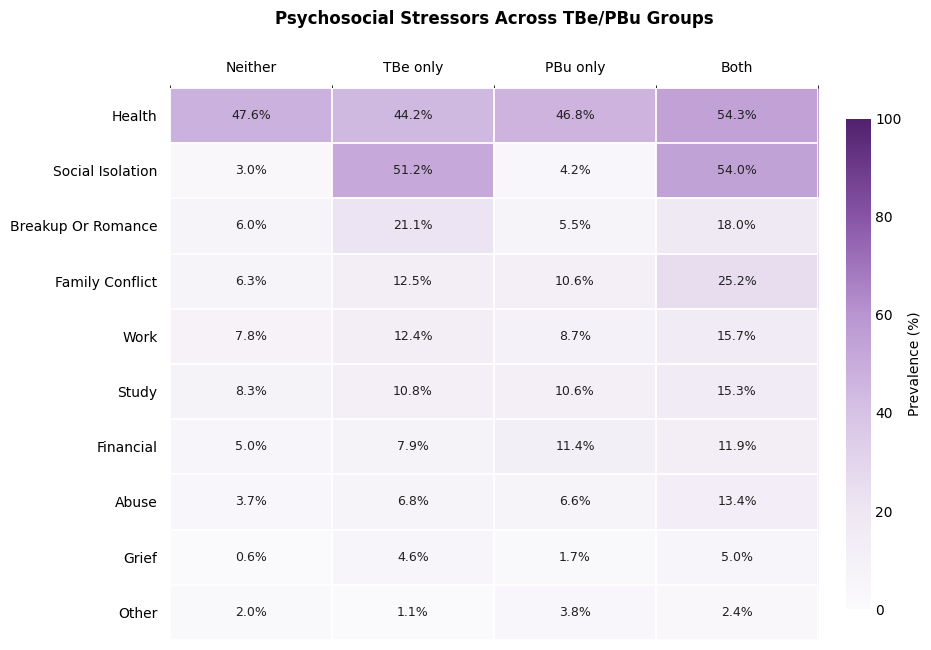

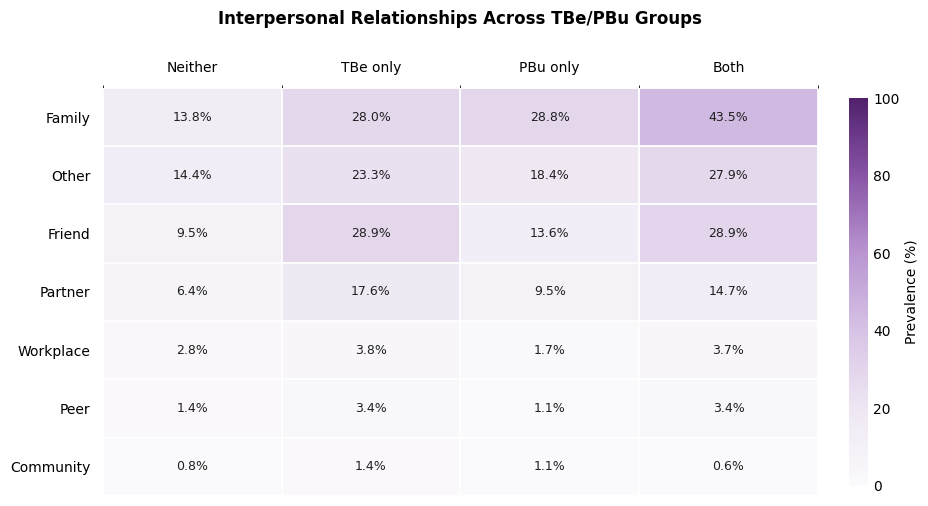

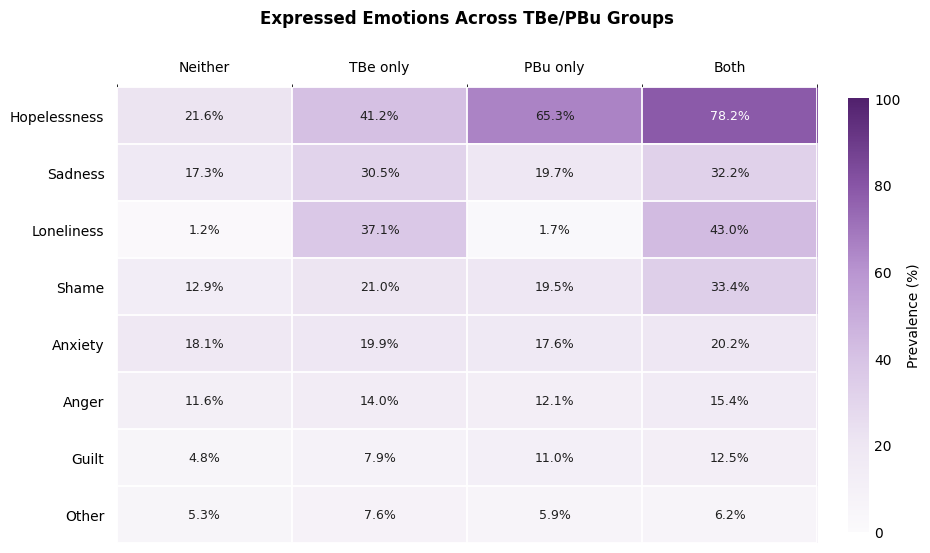

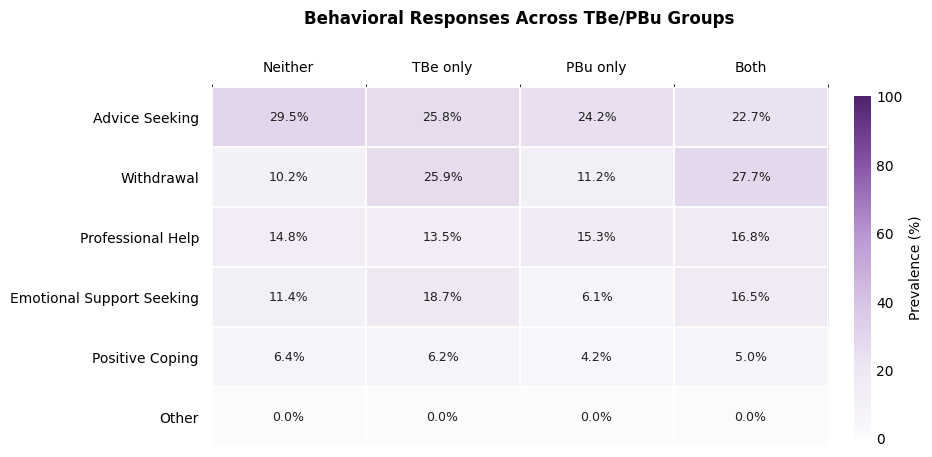

In [ ]:
# Four clearly labeled, publication-style prevalence heatmaps.
# A single, shared 0-100% color scale makes comparisons across fields valid.
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.titlesize": 12, "pdf.fonttype": 42, "ps.fonttype": 42,
    "savefig.facecolor": "white", "figure.facecolor": "white",
})

purple_colors = ["#FBFAFC", "#EEE7F3", "#D7C3E5", "#B995D1", "#8855A6", "#51216D"]
heat_cmap = LinearSegmentedColormap.from_list("publication_purple", purple_colors)
heat_norm = Normalize(vmin=0, vmax=100)
pct_columns = [f"{g}_pct" for g in GROUP_ORDER]
field_titles = {
    "stressors": "Psychosocial Stressors",
    "relationships": "Interpersonal Relationships",
    "emotions": "Expressed Emotions",
    "responses": "Behavioral Responses",
}

for field in TAG_FIELDS:
    sub = prevalence.loc[prevalence["field"].eq(field)].sort_values(
        "total_n", ascending=False
    )
    matrix = sub[pct_columns].to_numpy(dtype=float)
    n_rows, n_cols = matrix.shape
    fig, ax = plt.subplots(figsize=(9.4, max(3.6, 0.48 * n_rows + 1.8)))
    im = ax.imshow(matrix, cmap=heat_cmap, norm=heat_norm,
                   aspect="auto", interpolation="nearest")

    ax.set_xticks(np.arange(n_cols))
    ax.set_xticklabels(GROUP_ORDER, fontsize=10, color="black")
    ax.set_yticks(np.arange(n_rows))
    ax.set_yticklabels(sub["tag"].str.replace("_", " ").str.title(),
                       fontsize=10, color="black")
    ax.xaxis.tick_top()
    ax.tick_params(axis="both", which="major", length=0, pad=9)

    # Thin white boundaries between percentage cells.
    ax.set_xticks(np.arange(-0.5, n_cols, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n_rows, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.3)
    ax.tick_params(which="minor", bottom=False, left=False)

    for row_i in range(n_rows):
        for col_j in range(n_cols):
            value = matrix[row_i, col_j]
            rgba = heat_cmap(heat_norm(value))
            brightness = 0.2126 * rgba[0] + 0.7152 * rgba[1] + 0.0722 * rgba[2]
            ax.text(col_j, row_i, f"{value:.1f}%", ha="center", va="center",
                    fontsize=9, color="white" if brightness < 0.50 else "#202020")

    for spine in ax.spines.values():
        spine.set_visible(False)
    cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.04, shrink=0.95)
    cbar.set_label("Prevalence (%)", color="black")
    cbar.ax.tick_params(length=0)
    cbar.outline.set_visible(False)

    # Keep title color black, as requested.
    ax.set_title(f"{field_titles[field]} Across TBe/PBu Groups",
                 fontsize=12, color="black", fontweight="bold", pad=46)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"fig_prevalence_{field}.png", dpi=400,
                bbox_inches="tight", facecolor="white")
    fig.savefig(OUTPUT_DIR / f"fig_prevalence_{field}.pdf",
                bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)


## 4. Nominal logistic regression

**Why?** Our outcome is one of four *unordered* groups. This model estimates the association of each tag with each group relative to **Neither**, while holding the other included tags and post length constant.

- **Outcome (Y):** Neither (reference), TBe only, PBu only, or Both.
- **Predictors (X):** Binary codebook tags (`0` or `1`) plus log-transformed post word count to account for longer posts potentially mentioning more factors.
- **Result:** Adjusted relative risk ratio (RRR), 95% confidence interval (CI), and p-value for each tag and outcome comparison.

**Interpretation:** RRR = 2 for social isolation in *TBe only vs Neither* means that the *relative probability of TBe only versus Neither* is twice as large for posts with the tag, after adjusting for the other included predictors. It does **not** mean absolute probability doubles, and it is not causal.

Sparse tags may yield unstable model estimates. We exclude tags with fewer than `MIN_REGRESSION_TAG_COUNT` total positives or fewer than `MIN_PER_GROUP` positive or negative cases in any group, while retaining them in prevalence tables. The notebook reports these exclusions. We apply Benjamini-Hochberg correction to the regression tag p-values because the model estimates many associations. This correction is part of regression reporting and does **not** replace the group difference tests reserved for RQ4.


In [ ]:
# Choose sufficiently represented tags for stable multivariable estimation.
included, excluded = [], []
for item in FEATURE_META.itertuples(index=False):
    positive = group_tag_counts[item.feature]
    negative = group_sizes - positive
    reasons = []
    if int(positive.sum()) < MIN_REGRESSION_TAG_COUNT:
        reasons.append(f"total positive < {MIN_REGRESSION_TAG_COUNT}")
    if (positive < MIN_PER_GROUP).any():
        reasons.append(f"at least one group has < {MIN_PER_GROUP} positives")
    if (negative < MIN_PER_GROUP).any():
        reasons.append(f"at least one group has < {MIN_PER_GROUP} negatives")
    if reasons:
        excluded.append({"field": item.field, "tag": item.tag, "reason": "; ".join(reasons)})
    else:
        included.append(item.feature)

excluded_df = pd.DataFrame(excluded, columns=["field", "tag", "reason"])
excluded_df.to_csv(OUTPUT_DIR / "02a_regression_excluded_tags.csv", index=False)
print(f"Regressor tags included: {len(included)} / {len(FEATURES)}")
if not excluded_df.empty:
    print("Excluded from regression ONLY:")
    display(excluded_df)
if not included:
    raise ValueError("No tags meet regression stability thresholds; review the user settings")

# Post length is a control: longer posts have more room to mention more tags.
word_counts = df["text_clean"].astype(str).str.split().map(len)
X = TAGS[included].astype(float).copy()
X["log_word_count"] = np.log1p(word_counts).to_numpy()
X = sm.add_constant(X, has_constant="add")

# Map 0:Neither, 1:TBe only, 2:PBu only, 3:Both.
y = df["rq1_group"].cat.codes.astype(int)
assert (y >= 0).all()

# Fit unpenalized maximum-likelihood nominal/multinomial regression.
# A convergence failure is an analytical warning, not a result to conceal.
with warnings.catch_warnings(record=True) as model_warnings:
    warnings.simplefilter("always")
    model = sm.MNLogit(y, X)
    fitted = model.fit(method="newton", maxiter=200, disp=False)

for message in model_warnings:
    print(f"Model warning: {message.message}")
converged = bool(fitted.mle_retvals.get("converged", False))
if not converged or not np.isfinite(fitted.params.to_numpy()).all():
    raise RuntimeError(
        "Nominal regression did not converge to finite coefficients. "
        "Inspect sparse / correlated tags, or raise MIN_PER_GROUP and rerun. "
        "Do not report unstable model estimates."
    )

print(f"Nominal regression converged: {converged}")
print(f"Observations: {int(fitted.nobs):,} | outcome categories: {len(GROUP_ORDER)}")
print(f"McFadden pseudo R²: {fitted.prsquared:.3f} (descriptive fit, not prediction accuracy)")

Regressor tags included: 29 / 31
Excluded from regression ONLY:


,field,tag,reason
0,relationships,community,at least one group has < 5 positives
1,responses,other,total positive < 30; at least one group has < ...


Nominal regression converged: True
Observations: 3,519 | outcome categories: 4
McFadden pseudo R²: 0.269 (descriptive fit, not prediction accuracy)


In [ ]:
# Convert coefficients into RRR, 95% Wald confidence intervals and p-values.
# For statsmodels MNLogit, columns 0,1,2 compare outcome codes 1,2,3 vs code 0.
# Our explicitly ordered groups guarantee code 0 = Neither.
z_975 = norm.ppf(0.975)
model_rows = []
for outcome_idx, outcome_name in enumerate(GROUP_ORDER[1:]):
    for predictor in X.columns:
        beta = float(fitted.params.loc[predictor].iloc[outcome_idx])
        se = float(fitted.bse.loc[predictor].iloc[outcome_idx])
        p = float(fitted.pvalues.loc[predictor].iloc[outcome_idx])
        meta = FEATURE_META.loc[FEATURE_META["feature"].eq(predictor)]
        field = meta["field"].iat[0] if len(meta) else "control"
        tag = meta["tag"].iat[0] if len(meta) else predictor
        model_rows.append({
            "comparison": f"{outcome_name} vs Neither",
            "outcome": outcome_name, "field": field, "tag": tag,
            "predictor": predictor, "coef_log_RRR": beta,
            "std_error": se, "RRR": float(np.exp(beta)),
            "CI95_low": float(np.exp(beta - z_975 * se)),
            "CI95_high": float(np.exp(beta + z_975 * se)),
            "p_value": p,
        })

regression = pd.DataFrame(model_rows)
regression["q_fdr"] = np.nan
is_tag = regression["field"].ne("control")
regression.loc[is_tag, "q_fdr"] = multipletests(
    regression.loc[is_tag, "p_value"], method="fdr_bh"
)[1]
regression["significant_fdr_05"] = regression["q_fdr"].lt(FDR_ALPHA)
regression = regression.sort_values(["outcome", "q_fdr"], na_position="last")
regression.to_csv(OUTPUT_DIR / "02_multinomial_relative_risk_ratios.csv", index=False)

for outcome in GROUP_ORDER[1:]:
    print(f"\nAdjusted associations: {outcome} versus Neither (top 5 by FDR)")
    subset = regression.loc[(regression["outcome"] == outcome) & is_tag,
                            ["field", "tag", "RRR", "CI95_low", "CI95_high", "p_value", "q_fdr"]]
    display(subset.head(5).round(4).reset_index(drop=True))


Adjusted associations: TBe only versus Neither (top 5 by FDR)


,field,tag,RRR,CI95_low,CI95_high,p_value,q_fdr
0,stressors,social isolation,14.6400,9.7850,21.9039,0.0,0.0
1,emotions,loneliness,9.9061,5.5091,17.8124,0.0,0.0
2,stressors,breakup or romance,3.8430,2.5327,5.8312,0.0,0.0
3,emotions,hopelessness,1.7913,1.4198,2.2601,0.0,0.0
4,stressors,grief,8.1306,3.5010,18.8819,0.0,0.0



Adjusted associations: PBu only versus Neither (top 5 by FDR)


,field,tag,RRR,CI95_low,CI95_high,p_value,q_fdr
0,emotions,hopelessness,6.6025,5.1015,8.5451,0.0000,0.0000
1,relationships,family,2.1760,1.5066,3.1428,0.0000,0.0002
2,stressors,financial,2.0298,1.2976,3.1750,0.0019,0.0093
3,emotions,guilt,1.8424,1.1774,2.8832,0.0075,0.0326
4,relationships,other,1.5149,1.0590,2.1671,0.0230,0.0769



Adjusted associations: Both versus Neither (top 5 by FDR)


,field,tag,RRR,CI95_low,CI95_high,p_value,q_fdr
0,emotions,hopelessness,8.3100,6.2979,10.9648,0.0000,0.0000
1,stressors,social isolation,12.8069,8.1986,20.0056,0.0000,0.0000
2,emotions,loneliness,12.3310,6.6778,22.7701,0.0000,0.0000
3,stressors,breakup or romance,3.0126,1.8495,4.9071,0.0000,0.0001
4,stressors,grief,6.1181,2.4667,15.1745,0.0001,0.0006


## 5. What to report for RQ1

**Figure:** Four prevalence heatmaps (one per annotation field). The cell values are percentages of all posts **within that group**.

**Table 1:** One concise prevalence table with counts and percentages for the most informative tags. Full prevalence data are saved in `01_prevalence_by_group.csv`.

**Table 2:** A compact nominal logistic regression table with the strongest adjusted associations for each outcome compared with **Neither**. Report RRR, 95% CI, and FDR-adjusted p-value. The complete estimates are saved in `02_multinomial_relative_risk_ratios.csv`.

**Leave for RQ4:** Chi-square tests, Fisher pairwise tests, and their significance tables. Do not repeat them here.

**Quality and interpretation notes:** The notebook checks observed tags and evidence-field coverage but does not judge semantic correctness. The `relationships: other` evidence header needs confirmation against codebook v2.0; `responses: other` is an allowed tag not observed here. Some evidence quotes may differ from cleaned text after normalization. The data include historical review flags despite your team's review. Interpret results as observational associations, not causal effects or clinical risk estimates.


In [ ]:
# One short regression table: five strongest tag associations for each comparison.
# All results, including nonsignificant coefficients, remain in the full CSV.
compact_regression = (
    regression.loc[regression["field"].ne("control")]
    .sort_values(["outcome", "q_fdr"])
    .groupby("outcome", sort=False)
    .head(5)
    .loc[:, ["outcome", "field", "tag", "RRR", "CI95_low", "CI95_high", "q_fdr"]]
    .copy()
)
compact_regression.to_csv(OUTPUT_DIR / "02b_compact_regression_results.csv", index=False)
print("Compact RQ1 regression table (top five by adjusted p-value in each comparison):")
display(compact_regression.round(4).reset_index(drop=True))

# Export aggregate output only. Do not export source Reddit text or evidence quotes.
summary = pd.DataFrame([
    {"metric": "Source worksheet", "value": SHEET_NAME},
    {"metric": "Codebook version", "value": "MINDMINER Master Annotation Codebook v2.0"},
    {"metric": "Rows in source", "value": initial_rows},
    {"metric": "Unique posts in analysis", "value": len(df)},
    {"metric": "Repeated texts removed", "value": int(duplicates.sum())},
    {"metric": "Source rows historically flagged for review", "value": int(flagged.sum())},
    {"metric": "Excluded review flagged", "value": EXCLUDE_REVIEW_FLAGGED},
    {"metric": "Codebook-defined tags", "value": len(FEATURES)},
    {"metric": "Observed tags", "value": int(feature_counts.gt(0).sum())},
    {"metric": "Positive tags without evidence", "value": int(missing_evidence_total)},
    {"metric": "Evidence quotes not exact normalized text substrings (informational)",
     "value": int(codebook_audit["evidence_not_exact_substring_n"].sum())},
    {"metric": "Tags included in nominal regression", "value": len(included)},
    {"metric": "Regression converged", "value": converged},
    {"metric": "Methods run", "value": "Prevalence + nominal logistic regression"},
] + [{"metric": f"Group: {g}", "value": int(group_sizes[g])} for g in GROUP_ORDER])
summary.to_csv(OUTPUT_DIR / "00_data_and_analysis_summary.csv", index=False)

print("\nRQ1 simplified analysis complete. Outputs:")
for file in sorted(OUTPUT_DIR.iterdir()):
    print(" ", file.name)
print("\nThe source workbook was not changed.")


Compact RQ1 regression table (top five by adjusted p-value in each comparison):


,outcome,field,tag,RRR,CI95_low,CI95_high,q_fdr
0,Both,emotions,hopelessness,8.3100,6.2979,10.9648,0.0000
1,Both,stressors,social isolation,12.8069,8.1986,20.0056,0.0000
2,Both,emotions,loneliness,12.3310,6.6778,22.7701,0.0000
3,Both,stressors,breakup or romance,3.0126,1.8495,4.9071,0.0001
4,Both,stressors,grief,6.1181,2.4667,15.1745,0.0006
5,PBu only,emotions,hopelessness,6.6025,5.1015,8.5451,0.0000
6,PBu only,relationships,family,2.1760,1.5066,3.1428,0.0002
7,PBu only,stressors,financial,2.0298,1.2976,3.1750,0.0093
8,PBu only,emotions,guilt,1.8424,1.1774,2.8832,0.0326
9,PBu only,relationships,other,1.5149,1.0590,2.1671,0.0769



RQ1 simplified analysis complete. Outputs:
  00_codebook_tag_and_evidence_audit.csv
  00_data_and_analysis_summary.csv
  01_prevalence_by_group.csv
  02_multinomial_relative_risk_ratios.csv
  02a_regression_excluded_tags.csv
  02b_compact_regression_results.csv
  fig_prevalence_emotions.pdf
  fig_prevalence_emotions.png
  fig_prevalence_relationships.pdf
  fig_prevalence_relationships.png
  fig_prevalence_responses.pdf
  fig_prevalence_responses.png
  fig_prevalence_stressors.pdf
  fig_prevalence_stressors.png

The source workbook was not changed.
